# Global Temperature Analysis and Forecasting
## Complete project: raw data → visual analysis → inference → modelling → evaluation → application

This notebook starts from `data/raw/monthly_csv.csv` and builds the entire project. **No previous notebook or precomputed model result is required.** Its workflow is data inspection, date auditing, cleaning, exploratory visualizations, statistical diagnostics, chronological experiment design, model training, uncertainty evaluation and serving.

Research questions:
1. How do the two reported anomaly series change over time?
2. Which forecast configurations generalize under a chronological evaluation?
3. How reliable are calibrated prediction intervals and inferred trends?

The CSV is a historical snapshot. Retained observations end in October 2016, so final forecasts cover November 2016–October 2017. Baselines and the original release metadata are not supplied. Treat the results as a study of this dataset.

Install with `python -m pip install -e ".[dev]"`, then run all cells from the project root or notebook folder. The full training cell runs all models and regenerates reports. Saved notebook outputs are also included.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "config.json").exists(): ROOT = ROOT.parent
assert (ROOT / "data/raw/monthly_csv.csv").exists(), "Open from the project or notebooks folder"
sys.path.insert(0, str(ROOT / "src"))
from climate_ts.data import load_data, series_for
from climate_ts.exploration import explore, export_visualizations
from climate_ts.diagnostics import analyse_series
from climate_ts.models import supervised, fit_forecast, FEATURE_NAMES
from climate_ts.evaluation import split_origins, finite_quantile
config = json.loads((ROOT / "config.json").read_text())
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and inspect the original CSV

Before parsing or modelling, examine the raw column types, first and last records, counts, missingness and numerical range. `Source` identifies a separate series. `Date` contains mixed date formats. `Mean` is treated as an anomaly in °C from the dataset family, not absolute global temperature.

In [2]:
raw = pd.read_csv(ROOT / "data/raw/monthly_csv.csv")
display(raw.head(8))
display(raw.tail(8))
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum()}))
display(raw.groupby("Source").Mean.describe())
print("Raw shape:", raw.shape)

,Source,Date,Mean
0,GCAG,09-10-2017,0.6895
1,GISTEMP,09-10-2017,0.6700
2,GCAG,06-11-2017,0.7851
3,GISTEMP,06-11-2017,0.8500
4,GCAG,06-10-2016,0.7872
5,GISTEMP,06-10-2016,0.9000
6,GCAG,06-09-2016,0.7986
7,GISTEMP,06-09-2016,0.8200


,Source,Date,Mean
3280,GCAG,1880-04-06,-0.0499
3281,GISTEMP,1880-04-06,-0.2700
3282,GCAG,1880-03-06,-0.1357
3283,GISTEMP,1880-03-06,-0.1800
3284,GCAG,1880-02-06,-0.1229
3285,GISTEMP,1880-02-06,-0.2100
3286,GCAG,1880-01-06,0.0009
3287,GISTEMP,1880-01-06,-0.3000


,dtype,missing
Source,str,0
Date,str,0
Mean,float64,0


,count,mean,std,min,25%,50%,75%,max
Source,,,,,,,,
GCAG,1644.0,0.047112,0.321873,-0.6796,-0.190625,-0.02165,0.25215,0.9913
GISTEMP,1644.0,0.022305,0.338325,-0.7800,-0.230000,-0.05000,0.23000,1.0600


Raw shape: (3288, 3)


## 2. Audit dates and prepare the modelling table

Parse ISO strings as year-month-day and the other accepted format as day-month-year. A blanket mixed-date parser with `dayfirst=True` can misread older ISO dates. Reduce parsed dates to monthly keys, sort within source and reject duplicate source-month keys.

The input has a disconnected tail after 11 missing months. Preserve those records in quarantine instead of guessing dates. Retain the uninterrupted prefix, with no interpolation or modification of temperature values. Raw file hashing makes provenance auditable.

In [3]:
clean, quarantine, audit = load_data(ROOT / "data/raw/monthly_csv.csv")
display(pd.Series({k:audit[k] for k in ["input_rows","retained_rows","quarantined_rows","start","end","format_counts"]}))
display(quarantine)
display(clean[clean.raw_date.isin(["1899-12-06","06-12-1900"])][["source","raw_date","date","value"]])
print("Raw SHA-256:", audit["raw_sha256"])
assert len(clean) + len(quarantine) == len(raw)
display(clean.groupby("source").value.describe())

input_rows                                             3288
retained_rows                                          3284
quarantined_rows                                          4
start                                               1880-01
end                                                 2016-10
format_counts       {'YYYY-MM-DD': 480, 'DD-MM-YYYY': 2808}
dtype: object

,source,date,value,raw_date,csv_row,reason
0,GCAG,2017-10-01,0.6895,09-10-2017,2,Disconnected tail after first missing month; d...
1,GCAG,2017-11-01,0.7851,06-11-2017,4,Disconnected tail after first missing month; d...
2,GISTEMP,2017-10-01,0.6700,09-10-2017,3,Disconnected tail after first missing month; d...
3,GISTEMP,2017-11-01,0.8500,06-11-2017,5,Disconnected tail after first missing month; d...


,source,raw_date,date,value
239,GCAG,1899-12-06,1899-12-01,-0.1656
251,GCAG,06-12-1900,1900-12-01,0.0320
1881,GISTEMP,1899-12-06,1899-12-01,-0.2700
1893,GISTEMP,06-12-1900,1900-12-01,-0.1400


Raw SHA-256: c6272a009f1ada973116261f8d4a5f17e3f1a654b686ed4921e9c27d3e89d8ee


,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
GCAG,1642.0,0.046271,0.321161,-0.6796,-0.191075,-0.02175,0.250575,0.9913
GISTEMP,1642.0,0.021407,0.337534,-0.7800,-0.230000,-0.05000,0.220000,1.0600


## 3. Exploratory data analysis and visualizations

Start with a single source so reference-baseline differences do not get averaged away. Both sources are available in the exported gallery and the interactive dashboard. The following cell computes every EDA summary directly from `clean`, then exports 15 publication-sized PNG figures. The plotting implementation is in `src/climate_ts/exploration.py`.

Change `SOURCE` to inspect the other source. This choice affects the walkthrough examples; the final pipeline always evaluates both sources.

In [4]:
SOURCE = "GISTEMP"
series = series_for(clean, SOURCE)
prepared = explore(clean)
figure_index = export_visualizations(ROOT, clean, prepared)
prefix = SOURCE.lower()
print("Exported EDA figures:", len(figure_index))
def show_figure(name):
    display(Image(filename=str(ROOT / "reports/figures" / f"{prefix}_{name}.png")))

C:\Users\subar\Documents\Codex\2026-10-12\inn\outputs\climate-forecasting\src\climate_ts\exploration.py:39: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a, aci = acf(s.diff().dropna(), nlags=36, alpha=.05)
C:\Users\subar\Documents\Codex\2026-10-12\inn\outputs\climate-forecasting\src\climate_ts\exploration.py:39: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a, aci = acf(s.diff().dropna(), nlags

Exported EDA figures: 15


### 3.1 Monthly trends, smoothing and annual means

The monthly series shows short-run noise. Trailing 12- and 60-month means help examine the slower pattern without centered windows. Only full 12-month years enter annual aggregation; the incomplete final year is excluded from annual trend inference.

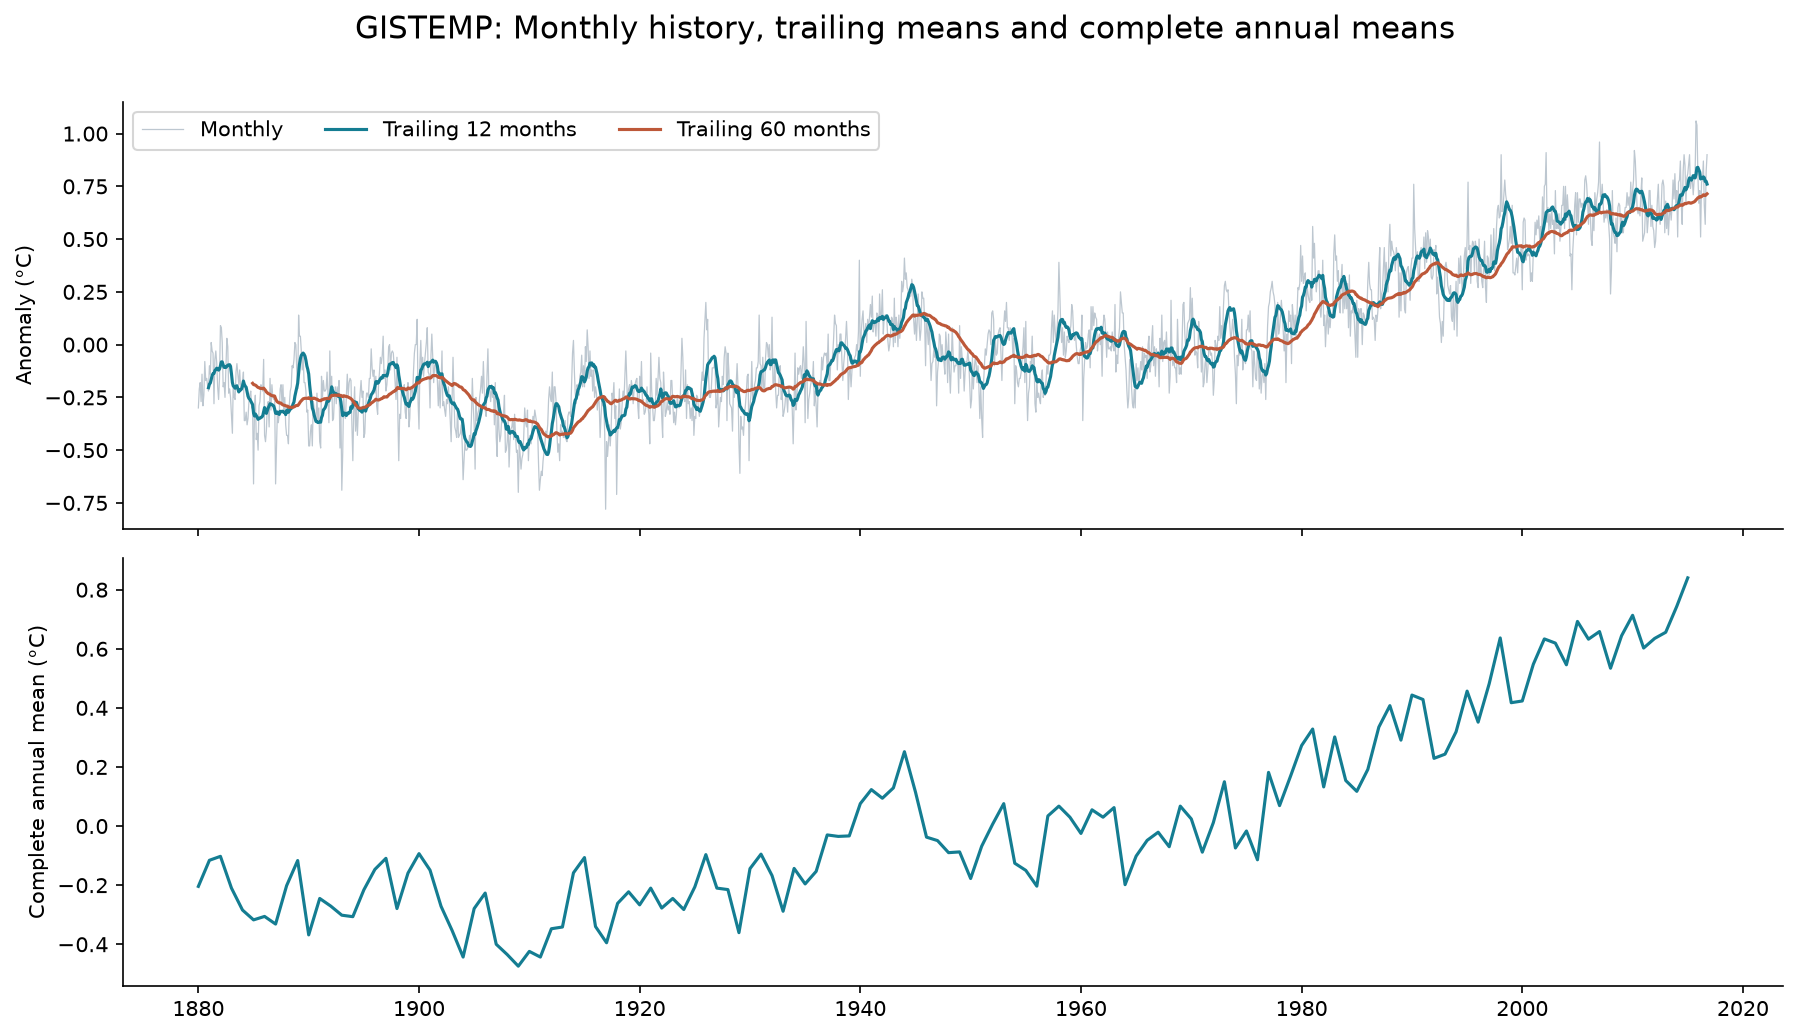

date
2011-01-01    0.602500
2012-01-01    0.635000
2013-01-01    0.655833
2014-01-01    0.743333
2015-01-01    0.840000
Freq: YS-JAN, Name: complete_annual_mean, dtype: float64

In [5]:
show_figure("history")
display(prepared[SOURCE]["annual"].tail().rename("complete_annual_mean"))

### 3.2 Year-by-month heatmap

Each row is a year and each column a calendar month. The color scale is centered at zero within the source. Read horizontal and vertical patterns separately: a warming shift across years is different from calendar seasonality. Unavailable cells are blank.

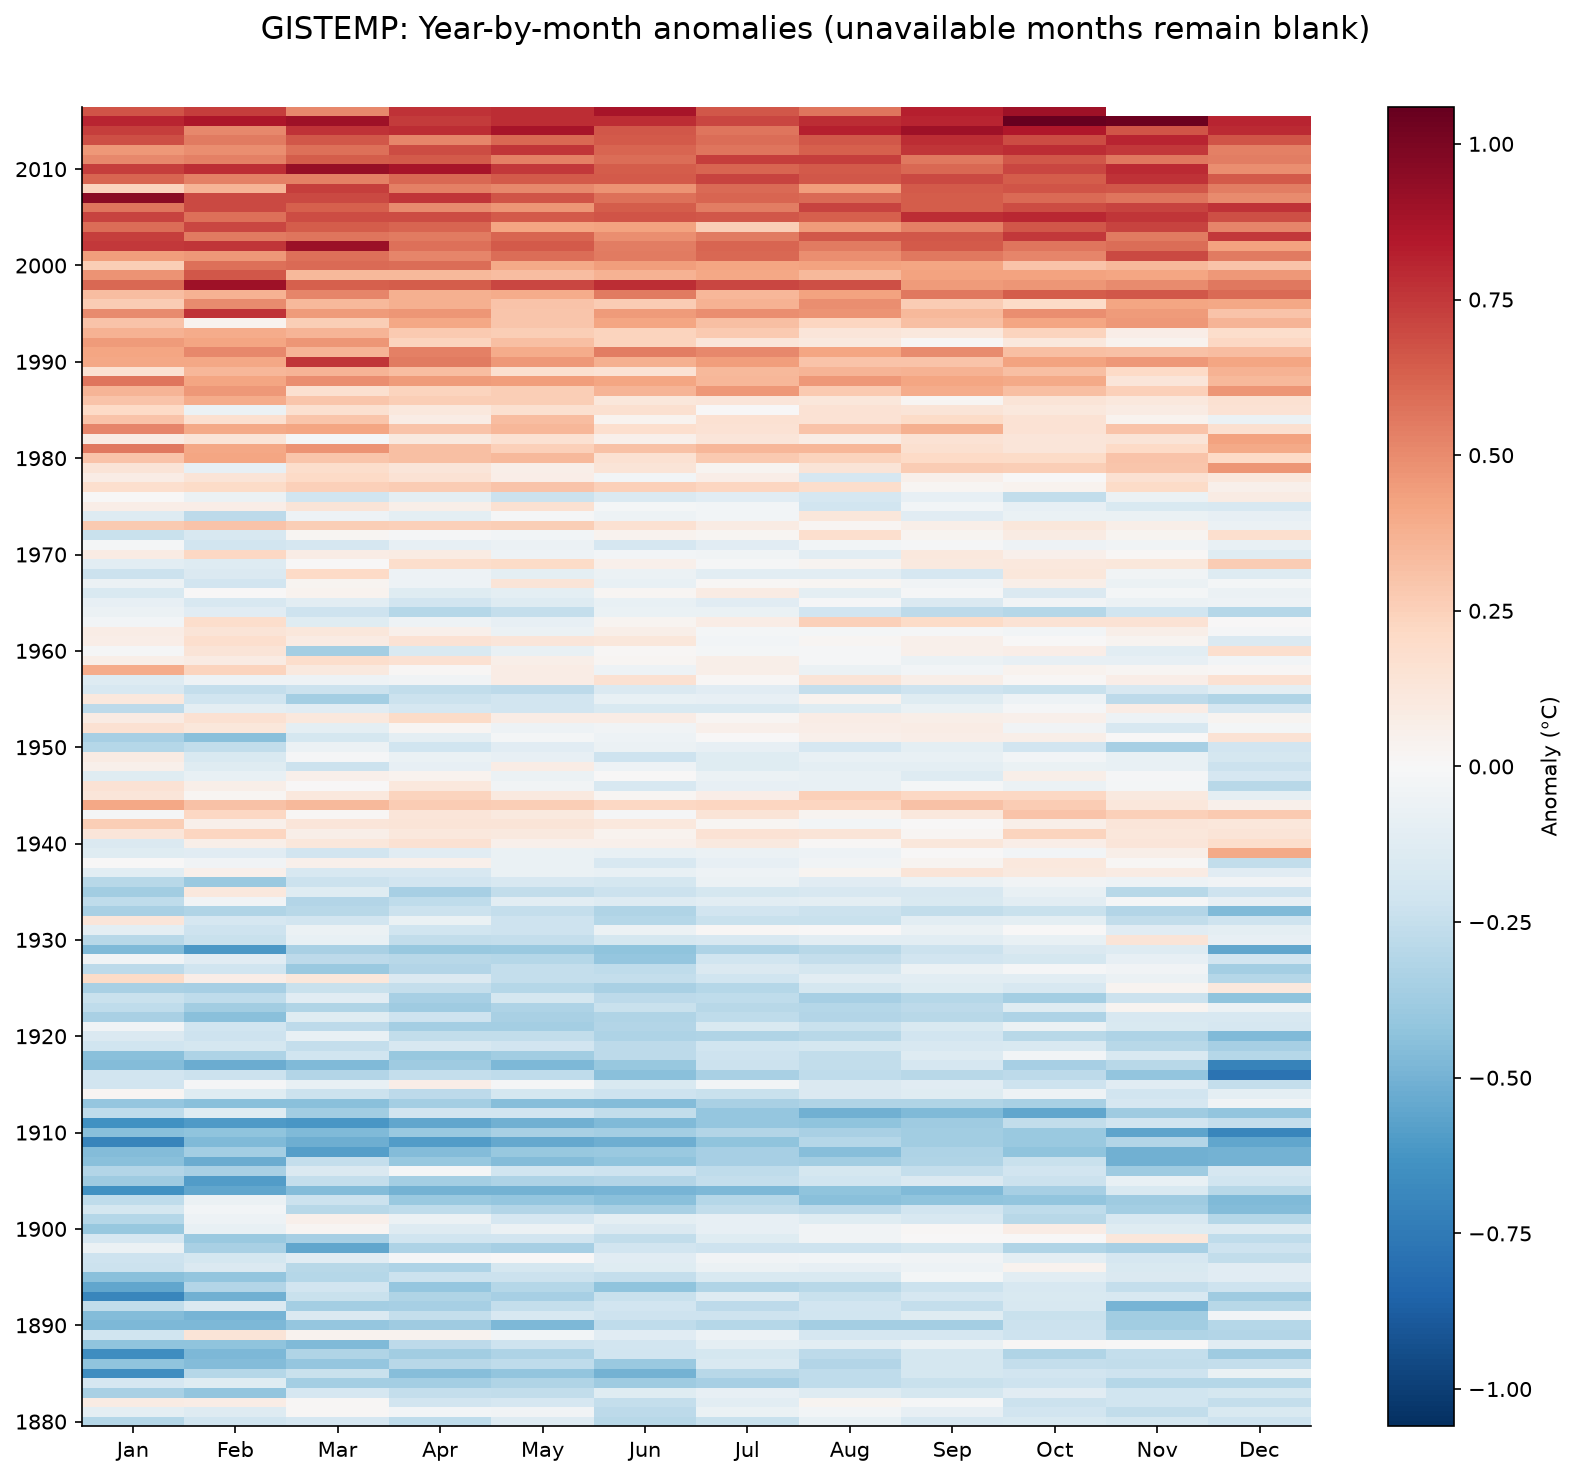

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2014,0.73,0.51,0.77,0.78,0.87,0.66,0.57,0.82,0.90,0.85,0.67,0.79
2015,0.81,0.86,0.90,0.74,0.78,0.78,0.71,0.78,0.81,1.06,1.04,0.81
2016,0.67,0.73,0.51,0.77,0.78,0.87,0.66,0.57,0.82,0.90,NaN,NaN


In [6]:
show_figure("heatmap")
display(prepared[SOURCE]["heatmap"].tail(3))

### 3.3 Distribution and decade shifts

The histogram describes the pooled historical observations. Decade boxes reveal how that pooled distribution combines regimes with different levels. Do not interpret it as a stationary probability distribution or use a whole-history outlier rule to delete recent high anomalies.

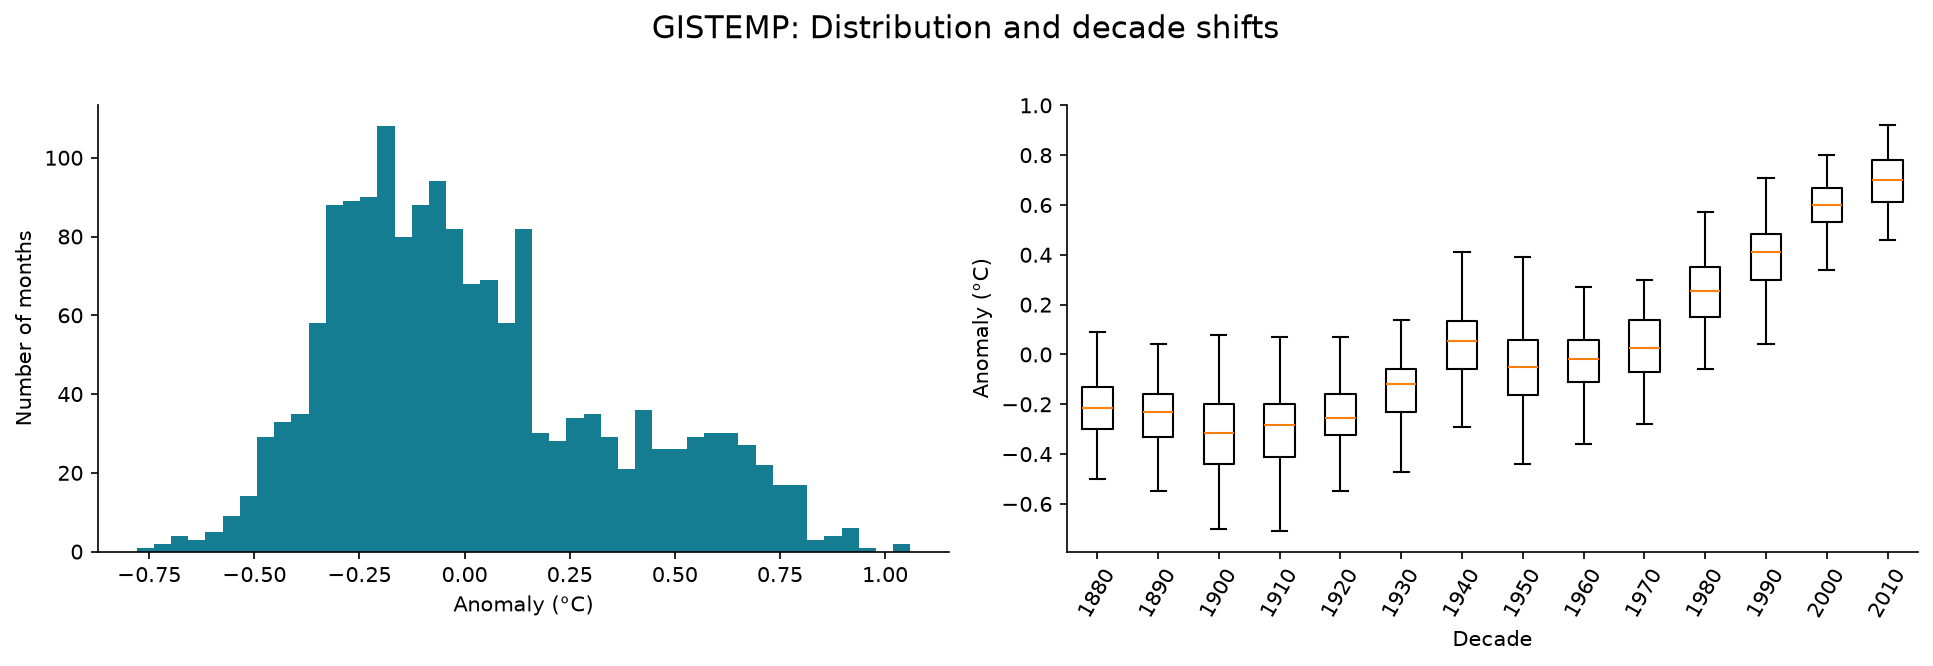

In [7]:
show_figure("distributions")

### 3.4 Calendar-month distributions

These boxes contain observations across the full history. Differences in their locations can reflect the mix of warming regimes as well as a monthly effect. Global anomaly series should not be assumed to have the seasonal cycle of local absolute temperatures.

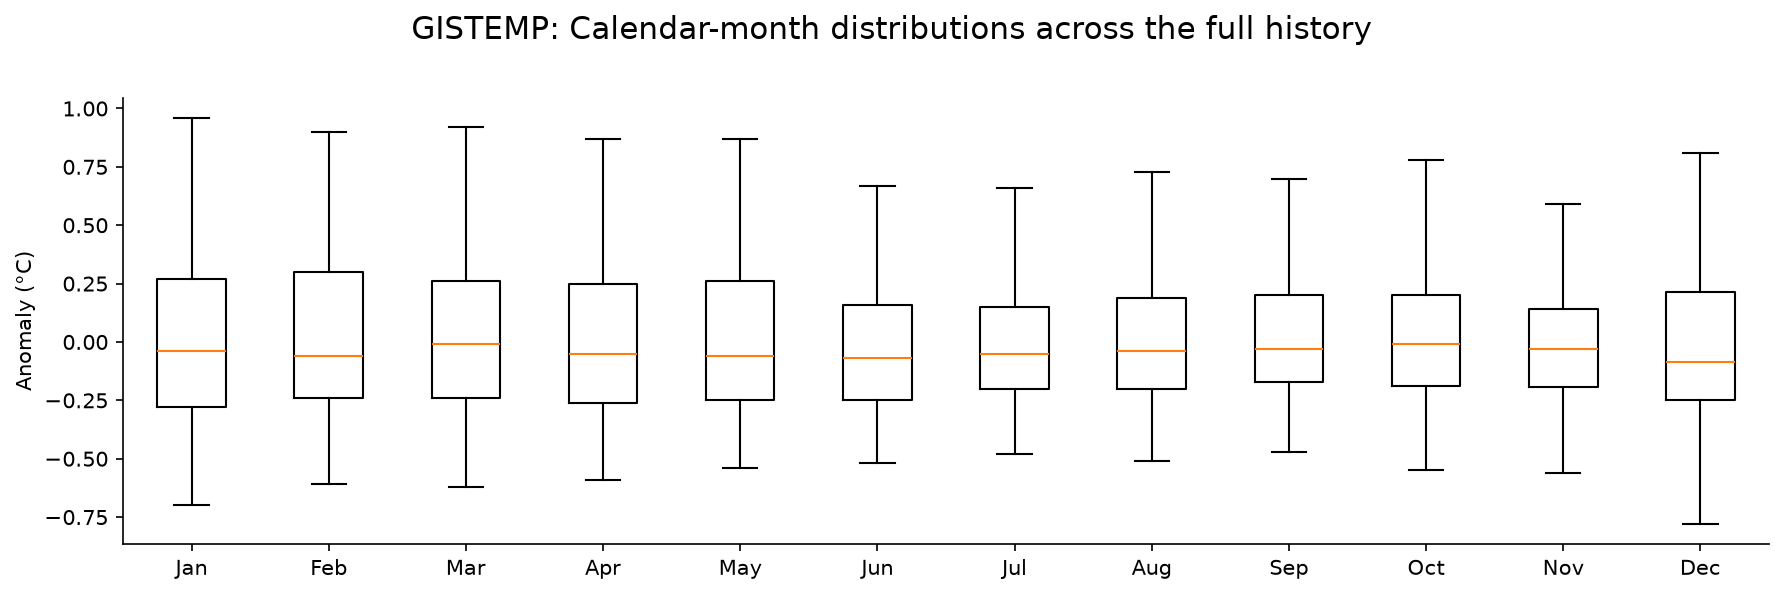

In [8]:
show_figure("months")

### 3.5 Variability and first differences

Trailing 12-month standard deviation summarizes local variation. First differences show changes from one month to the next. These views help distinguish changes in level from short-term variation.

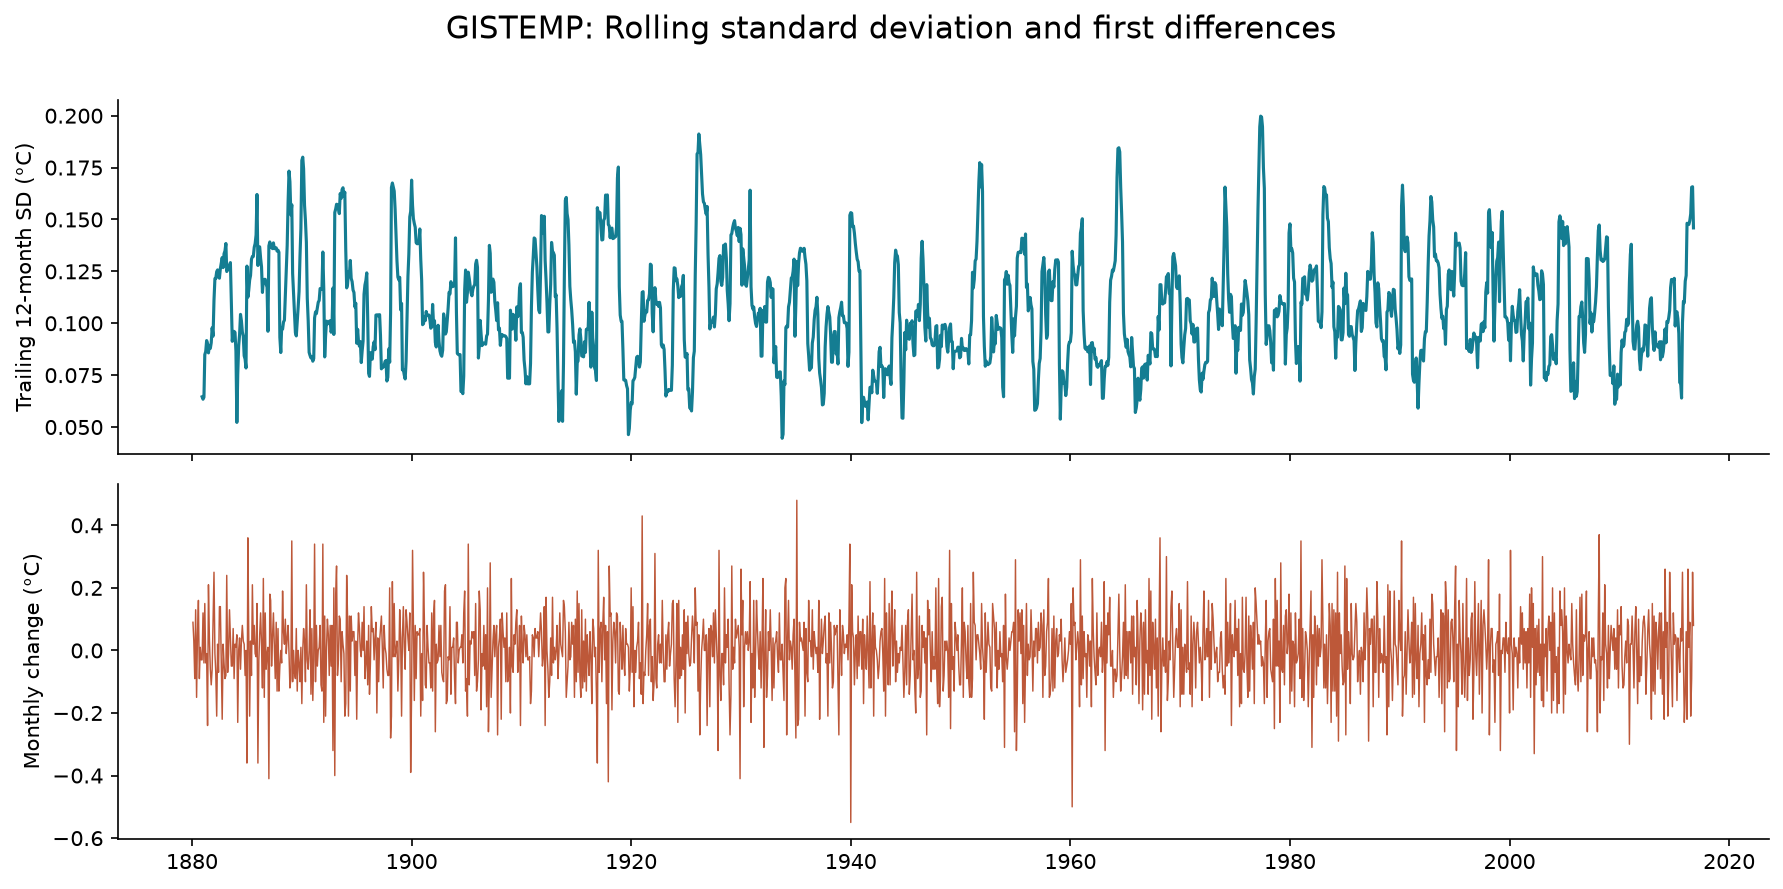

In [9]:
show_figure("variability")

### 3.6 Robust STL decomposition

Decompose observations into a smooth trend, a 12-month seasonal component and a remainder. Full-history STL uses later data to estimate earlier components, so it is **descriptive only** and never enters the forecast backtest features.

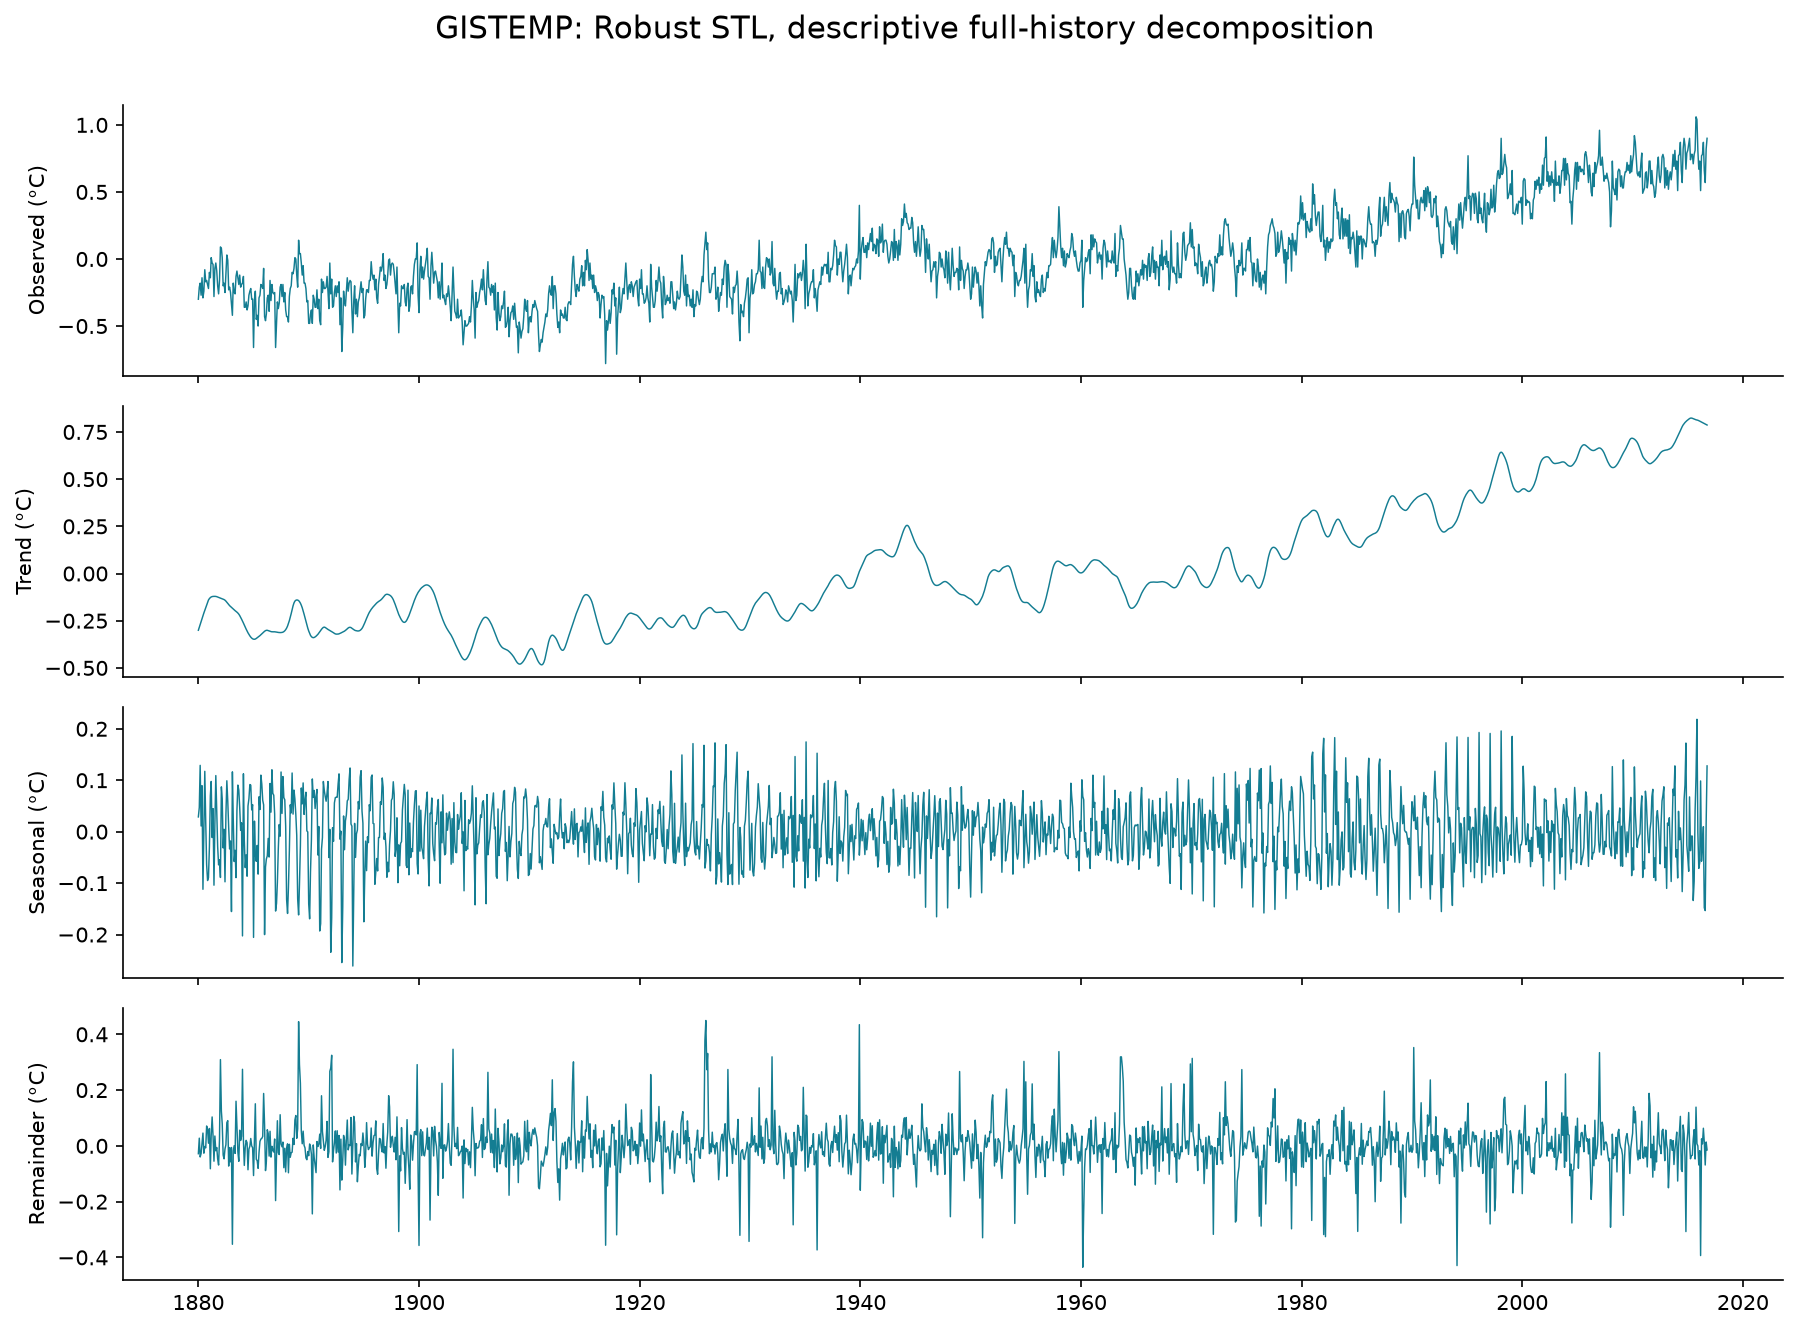

In [10]:
show_figure("decomposition")

### 3.7 Serial dependence: ACF and PACF

These diagnostics use first differences and 36 monthly lags. Dotted lines are approximate 95% bounds. Isolated exceedances across many lags should not be treated as automatic model-order decisions.

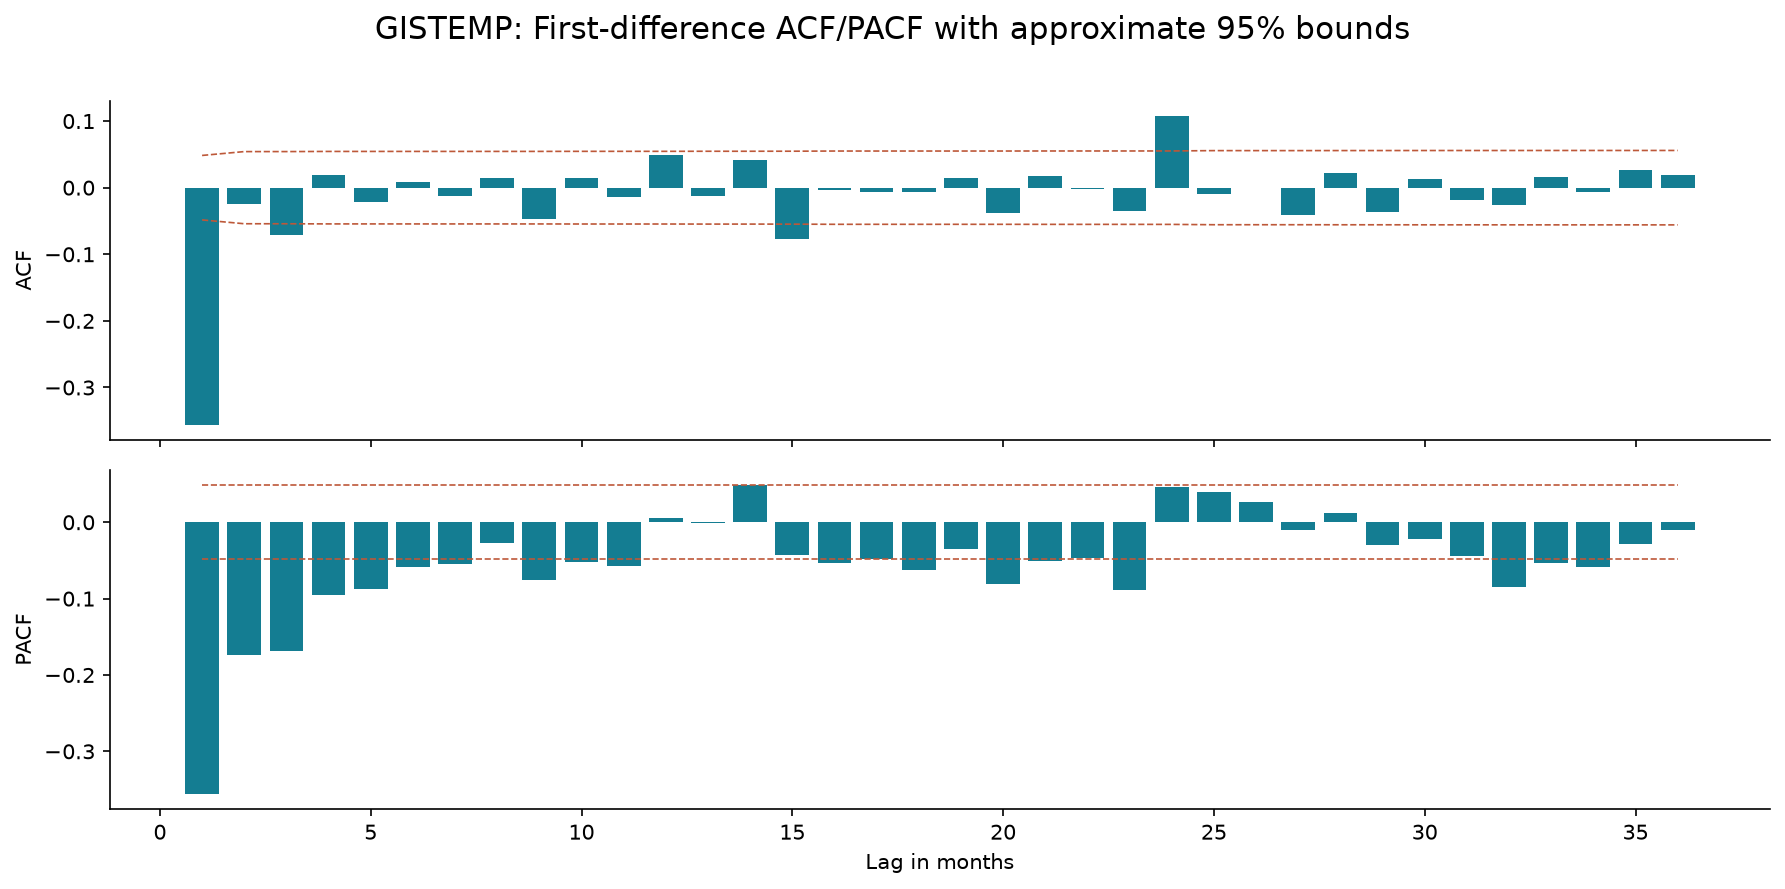

In [11]:
show_figure("autocorrelation")

### 3.8 Compare sources in levels and changes

Level correlation is affected by the common trend. First-difference correlation describes co-movement in monthly changes. Distinct baselines and shared underlying observations prevent treating the two sources as independent replications.

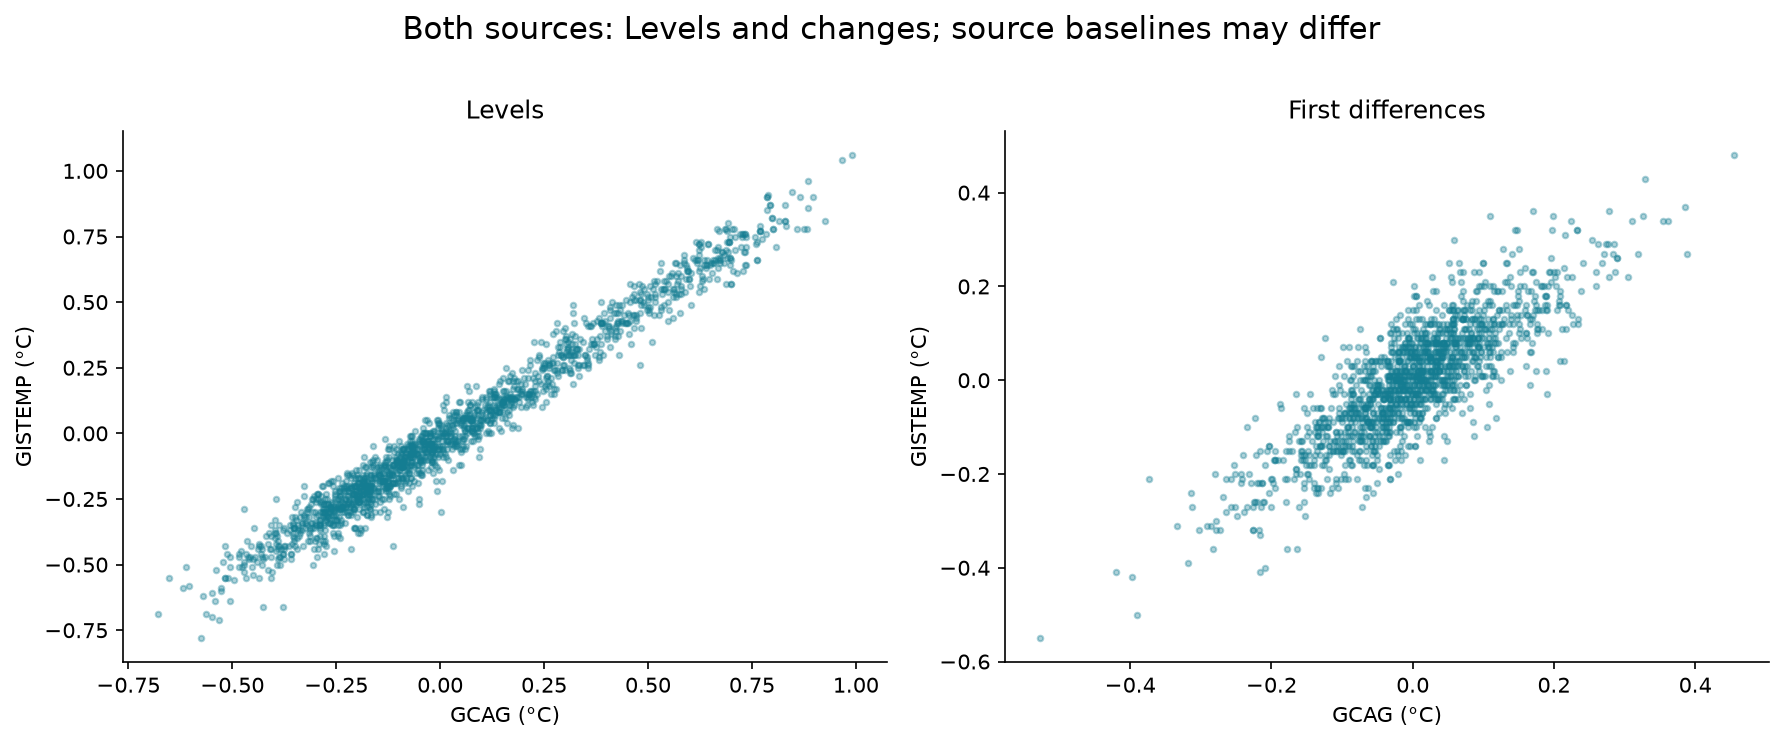

,level_correlation,difference_correlation,mean_GCAG_minus_GISTEMP
0,0.9847,0.83454,0.024864


In [12]:
display(Image(filename=str(ROOT / "reports/figures/both sources_comparison.png")))
wide = clean.pivot(index="date", columns="source", values="value")
display(pd.DataFrame({"level_correlation":[wide.corr().iloc[0,1]],
                      "difference_correlation":[wide.diff().dropna().corr().iloc[0,1]],
                      "mean_GCAG_minus_GISTEMP":[(wide.GCAG-wide.GISTEMP).mean()]}))

## 4. Statistical inference and stationarity

OLS slopes use complete annual means and HAC covariance with three annual lags. The full-history and since-1970 windows are descriptive choices, not causal designs. ADF has a unit-root null; KPSS has a stationarity null. Their assumptions and approximate p-value bounds matter.

An exploratory continuous-hinge search considers years with at least 20 observations on each side. The best year by BIC is a descriptive location, with search uncertainty omitted.

In [13]:
diagnostic, decomposition = analyse_series(series)
display(pd.DataFrame(diagnostic["trends"]))
display(pd.DataFrame(diagnostic["stationarity"]))
print("STL seasonal strength:", diagnostic["seasonal_strength"])
display(pd.Series(diagnostic["exploratory_break"]))
print("Stationarity warnings:", diagnostic["stationarity_notes"])

,window,start,end,n_years,slope_c_per_decade,lower_95,upper_95,p_value,HAC_lags_years
0,full_complete_years,1880,2015,136,0.069998,0.056630,0.083365,1.033907e-24,3
1,since_1970,1970,2015,46,0.175353,0.157675,0.193030,3.432899e-84,3


,series,adf_stat,adf_p,kpss_stat,kpss_p,adf_lags
0,level_with_trend,-3.700350,2.233419e-02,0.836717,0.01,25
1,first_difference,-11.465921,5.411614e-21,0.117456,0.10,24


STL seasonal strength: 0.24477514351906715


break_year                                                              1972
bic                                                                -196.8893
pre_slope_c_per_decade                                              0.036537
post_slope_c_per_decade                                             0.175116
linear_bic                                                       -108.420934
note                       Exploratory best single hinge among annual can...
dtype: object

Stationarity warnings: ['The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.', 'The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.', 'adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.', 'kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep th

## 5. Design the experiment before training

Each model uses a rolling 600-month training window and forecasts the next 12 months. Fifteen annual origins select the configuration, ten subsequent origins calibrate the fixed winner's intervals, and five final origins evaluate it. Target blocks do not overlap.

Earlier test observations may enter later annual refits once those observations would be available. Hyperparameters and the chosen configuration remain fixed. This evaluates annual updating, not a single five-year forecast.

In [14]:
origins = split_origins(len(series), config)
split_rows=[]
for phase, positions in origins.items():
    split_rows.append({"phase":phase,"origins":len(positions),"target_start":series.index[positions[0]],"target_end":series.index[positions[-1]+11]})
display(pd.DataFrame(split_rows))
display(pd.Series(config))

,phase,origins,target_start,target_end
0,selection,15,1986-11-01,2001-10-01
1,calibration,10,2001-11-01,2011-10-01
2,test,5,2011-11-01,2016-10-01


horizon                                                              12
train_window                                                        600
selection_months                                                    180
calibration_months                                                  120
test_months                                                          60
seed                                                                 42
candidates            [naive, seasonal_naive, drift, ets_damped, ari...
interval_levels                                              [0.8, 0.9]
dtype: object

## 6. Build causal features and compare model families

The ten fixed configurations cover naive, seasonal naive, drift, damped ETS, ARIMA, seasonal ARIMA, two Ridge penalties and two boosting depths. Model complexity is evaluated rather than assumed beneficial.

For machine learning, lags and rolling summaries end at t−1. Calendar terms and time index are known at the forecast origin. Scaling is learned only within the training fold. Later multi-step features use earlier predictions recursively.

In [15]:
origin = origins["selection"][0]
train = series.iloc[origin-config["train_window"]:origin]
X, y = supervised(train)
display(pd.DataFrame(X, columns=FEATURE_NAMES).head())
demo_prediction, demo_model, notes = fit_forecast("ridge_1", train, 12, config["seed"])
display(pd.DataFrame({"date":series.index[origin:origin+12],"prediction":demo_prediction,
                      "actual_for_scoring_only":series.iloc[origin:origin+12].to_numpy()}))

,lag_1,lag_2,lag_3,lag_6,lag_12,lag_24,mean_3,mean_12,std_12,change_12,month_sin,month_cos,time_years
0,0.11,0.03,-0.04,-0.07,0.09,-0.05,0.033333,-0.016667,0.082798,0.01,-5.000000e-01,8.660254e-01,2.000000
1,0.01,0.11,0.03,-0.17,-0.12,-0.04,0.050000,-0.023333,0.076956,-0.08,-2.449294e-16,1.000000e+00,2.083333
2,-0.26,0.01,0.11,-0.09,0.00,-0.11,-0.046667,-0.035000,0.098362,-0.14,5.000000e-01,8.660254e-01,2.166667
3,-0.13,-0.26,0.01,-0.04,-0.04,0.05,-0.126667,-0.045833,0.101033,-0.13,8.660254e-01,5.000000e-01,2.250000
4,-0.12,-0.13,-0.26,0.03,0.05,-0.17,-0.170000,-0.052500,0.103047,-0.08,1.000000e+00,6.123234e-17,2.333333


,date,prediction,actual_for_scoring_only
0,1986-11-01,0.118186,0.11
1,1986-12-01,0.126328,0.16
2,1987-01-01,0.134144,0.36
3,1987-02-01,0.114981,0.46
4,1987-03-01,0.120501,0.17
5,1987-04-01,0.113805,0.24
6,1987-05-01,0.109505,0.26
7,1987-06-01,0.110558,0.36
8,1987-07-01,0.097725,0.46
9,1987-08-01,0.101645,0.28


## 7. Train and run the complete pipeline

This cell starts from the raw CSV and regenerates all data audit, EDA, training, calibration, holdout, model, SQL, dashboard and report artifacts. It requires no existing results. It overwrites generated files within this project folder. Copy the folder before changing the experiment if you need to preserve an earlier run.

In [16]:
from climate_ts.pipeline import run
manifest = run(ROOT)
assert manifest["raw_sha256"] == audit["raw_sha256"]
print("Backtest fits:", manifest["fit_count"], "Failed fits:", manifest["failed_fits"])
print("Final model refits:", manifest["final_candidate_fits"])

Generating exploratory visualizations from audited observations


C:\Users\subar\Documents\Codex\2026-10-12\inn\outputs\climate-forecasting\src\climate_ts\exploration.py:39: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a, aci = acf(s.diff().dropna(), nlags=36, alpha=.05)
C:\Users\subar\Documents\Codex\2026-10-12\inn\outputs\climate-forecasting\src\climate_ts\exploration.py:39: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a, aci = acf(s.diff().dropna(), nlags

GCAG: selecting among 10 candidates on 15 origins


GCAG: locked champion ridge_1; calibrating intervals and evaluating holdout


GISTEMP: selecting among 10 candidates on 15 origins


GISTEMP: locked champion ridge_1; calibrating intervals and evaluating holdout


Finished in 83.6s. Open reports/dashboard.html


Backtest fits: 420 Failed fits: 0
Final model refits: 20


## 8. Evaluate selection and holdout results

MAE and RMSE are in °C. Seasonal MASE uses the origin's training seasonal-difference scale. Positive bias means overprediction. MAPE is avoided because anomaly values can cross zero. Keep the winner chosen before testing even when another model performs better in hindsight.

In [17]:
scores = pd.read_csv(ROOT / "artifacts/scores.csv")
display(scores[(scores.source == SOURCE) & (scores.phase == "selection")].sort_values("MAE"))
display(scores[(scores.source == SOURCE) & (scores.phase == "test")].sort_values("MAE"))
display(pd.DataFrame({s:{k:f[k] for k in ["champion","test_MAE","test_RMSE","MAE_improvement_percent"]}
                      for s,f in manifest["sources"].items()}).T)

,source,phase,model,MAE,RMSE,MASE,bias,n,origins
28,GISTEMP,selection,ridge_1,0.117257,0.147465,0.789476,-0.052382,180,15
29,GISTEMP,selection,ridge_10,0.117926,0.148138,0.794020,-0.055051,180,15
25,GISTEMP,selection,drift,0.125652,0.156995,0.843104,-0.043187,180,15
27,GISTEMP,selection,naive,0.125667,0.157579,0.843206,-0.046667,180,15
22,GISTEMP,selection,arima_111,0.127970,0.156129,0.859367,-0.037490,180,15
30,GISTEMP,selection,sarima_111_100,0.127978,0.155883,0.859486,-0.037952,180,15
26,GISTEMP,selection,ets_damped,0.129233,0.157036,0.867926,-0.047175,180,15
23,GISTEMP,selection,boosting_3,0.135193,0.164154,0.907988,-0.025079,180,15
24,GISTEMP,selection,boosting_5,0.143674,0.171954,0.965176,-0.025746,180,15
31,GISTEMP,selection,seasonal_naive,0.154389,0.196801,1.036104,-0.020500,180,15


,source,phase,model,MAE,RMSE,MASE,bias,n,origins
40,GISTEMP,test,sarima_111_100,0.106135,0.131852,0.698566,0.041925,60,5
32,GISTEMP,test,arima_111,0.107844,0.132637,0.709868,0.044097,60,5
39,GISTEMP,test,ridge_10,0.109216,0.135415,0.717658,0.047861,60,5
38,GISTEMP,test,ridge_1,0.110892,0.137951,0.728539,0.053528,60,5
36,GISTEMP,test,ets_damped,0.111916,0.137375,0.736715,0.048583,60,5
34,GISTEMP,test,boosting_5,0.114325,0.141792,0.753136,-0.010483,60,5
33,GISTEMP,test,boosting_3,0.115163,0.142243,0.758886,-0.012932,60,5
41,GISTEMP,test,seasonal_naive,0.115333,0.146652,0.759314,-0.028667,60,5
37,GISTEMP,test,naive,0.147833,0.186927,0.973958,0.093500,60,5
35,GISTEMP,test,drift,0.152513,0.192041,1.004802,0.102333,60,5


,champion,test_MAE,test_RMSE,MAE_improvement_percent
GCAG,ridge_1,0.098207,0.131446,17.212343
GISTEMP,ridge_1,0.110892,0.137951,3.850478


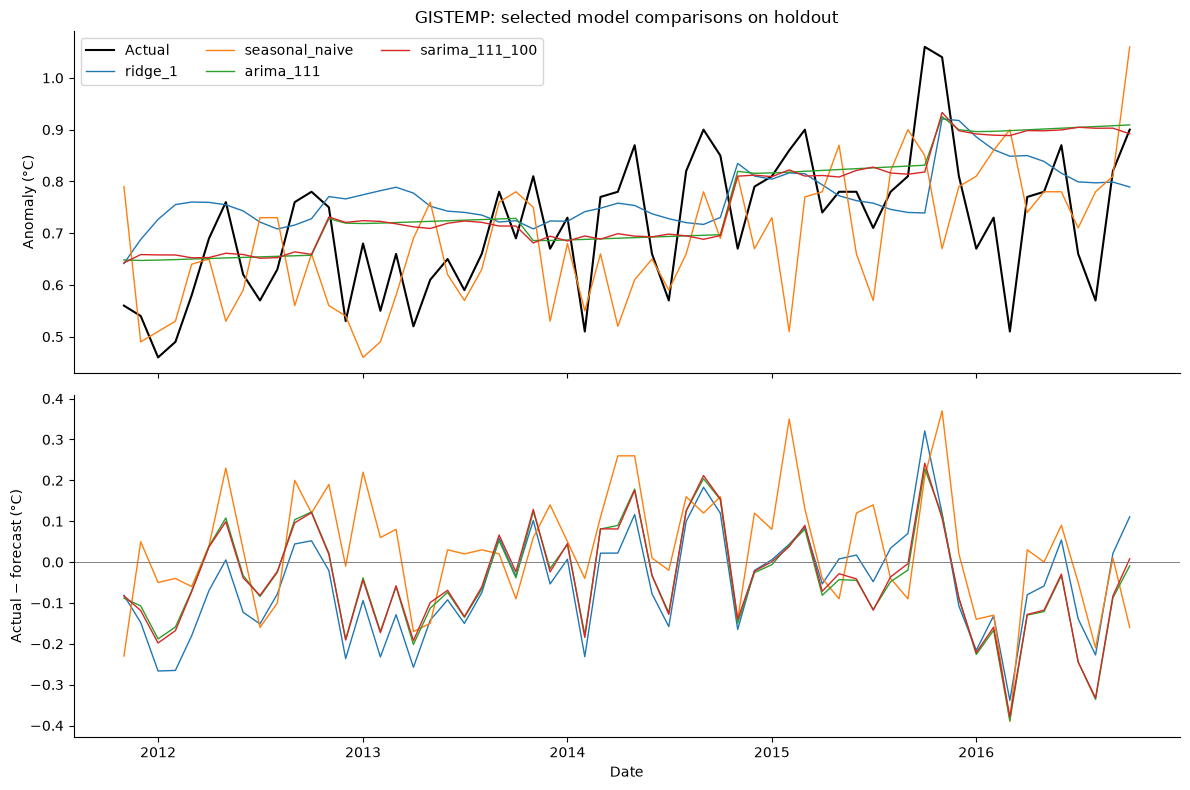

In [18]:
pred = pd.read_csv(ROOT / "artifacts/predictions.csv", parse_dates=["date","origin"])
MODELS = ["ridge_1", "seasonal_naive", "arima_111", "sarima_111_100"]
test = pred[(pred.source == SOURCE) & (pred.phase == "test")]
fig, axes = plt.subplots(2,1,figsize=(12,8),sharex=True)
actual = test[test.model == "naive"]
axes[0].plot(actual.date,actual.actual,color="black",label="Actual",lw=1.5)
for model in MODELS:
    g=test[test.model == model]
    axes[0].plot(g.date,g.prediction,label=model,lw=1)
    axes[1].plot(g.date,g.error,label=model,lw=1)
axes[0].set(title=f"{SOURCE}: selected model comparisons on holdout",ylabel="Anomaly (°C)")
axes[1].set(ylabel="Actual − forecast (°C)",xlabel="Date")
axes[1].axhline(0,color="gray",lw=.7)
axes[0].legend(ncol=3);fig.tight_layout();plt.show()

## 9. Calibrate prediction intervals and inspect uncertainty

The fixed winner has ten independent forecast-origin calibration errors per horizon, although temporal dependence can remain. For level c, the absolute-error radius uses rank ceil((n+1)c). With ten calibration errors, finite 80% and 90% intervals are available; 95% is rejected.

Coverage is measured on the held-out targets. Serial dependence and rolling refitting prevent claiming exact exchangeable-sample conformal guarantees. The paired annual-block bootstrap uses only five test blocks and provides weak uncertainty resolution.

In [19]:
cal = pred[(pred.source==SOURCE)&(pred.phase=="calibration")]
print("One-month 90% empirical radius:", finite_quantile(cal[cal.horizon==1].error,.9))
intervals = pd.read_csv(ROOT / "artifacts/interval_evaluation.csv")
display(intervals.groupby(["source","level"]).agg(coverage=("covered","mean"),interval_score=("interval_score","mean")))
display(pd.DataFrame({s:f["paired_comparison"] for s,f in manifest["sources"].items()}).T)

One-month 90% empirical radius: 0.1638735807094186


coverage  interval_score
source  level                          
GCAG    0.8    0.783333        0.466519
        0.9    0.866667        0.560797
GISTEMP 0.8    0.750000        0.500324
        0.9    0.916667        0.588994

,mae_gain_vs_seasonal_naive,bootstrap_lower_95,bootstrap_upper_95,blocks,note
GCAG,0.020418,-0.007969,0.048805,5,Exploratory paired annual-block bootstrap; onl...
GISTEMP,0.004441,-0.021872,0.033817,5,Exploratory paired annual-block bootstrap; onl...


## 10. Compare final forecasts from all model configurations

Each candidate is independently refitted through October 2016. Choose any models for an overlay, matching the dashboard's checkboxes. Only the fixed validation winner has intervals from separate calibration. Selecting overlays does not change model-selection decisions.

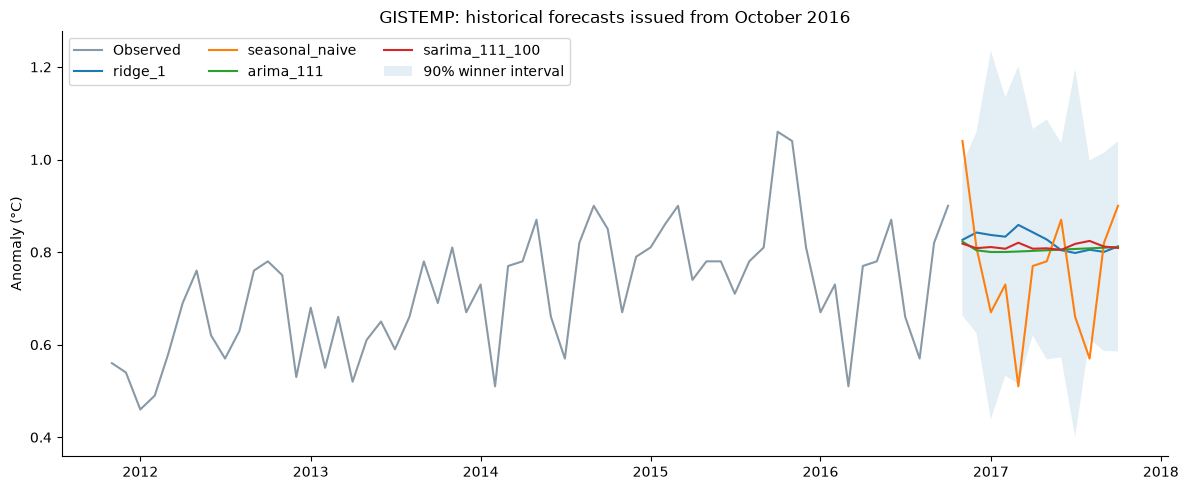

model,arima_111,boosting_3,boosting_5,drift,ets_damped,naive,ridge_1,ridge_10,sarima_111_100,seasonal_naive
date,,,,,,,,,,
2016-11-01,0.8226,0.8443,0.8542,0.9015,0.8108,0.9,0.8265,0.8146,0.8182,1.04
2016-12-01,0.8039,0.7817,0.7843,0.9031,0.8110,0.9,0.8423,0.8284,0.8085,0.81
2017-01-01,0.8001,0.7923,0.7953,0.9046,0.8111,0.9,0.8369,0.8242,0.8109,0.67
2017-02-01,0.8002,0.7828,0.7894,0.9061,0.8112,0.9,0.8333,0.8252,0.8072,0.73
2017-03-01,0.8013,0.7954,0.8124,0.9077,0.8113,0.9,0.8587,0.8464,0.8202,0.51
2017-04-01,0.8026,0.8484,0.8590,0.9092,0.8114,0.9,0.8428,0.8409,0.8073,0.77
2017-05-01,0.8040,0.7945,0.8096,0.9108,0.8116,0.9,0.8272,0.8218,0.8082,0.78
2017-06-01,0.8053,0.7951,0.8167,0.9123,0.8117,0.9,0.8041,0.8023,0.8047,0.87
2017-07-01,0.8067,0.8189,0.8346,0.9138,0.8118,0.9,0.7981,0.7885,0.8177,0.66


In [20]:
future = pd.read_csv(ROOT / "artifacts/candidate_forecasts.csv",parse_dates=["date"])
issued = pd.read_csv(ROOT / "artifacts/forecast.csv",parse_dates=["date"])
g=future[future.source==SOURCE]
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(series.iloc[-60:].index,series.iloc[-60:],label="Observed",color="#8999a6")
for model in MODELS:
    p=g[g.model==model];ax.plot(p.date,p.prediction,label=model)
band=issued[(issued.source==SOURCE)&(issued.level==.9)]
ax.fill_between(band.date,band.lower,band.upper,alpha=.12,label="90% winner interval")
ax.set(title=f"{SOURCE}: historical forecasts issued from October 2016",ylabel="Anomaly (°C)")
ax.legend(ncol=3);fig.tight_layout();plt.show()
display(g.pivot(index="date",columns="model",values="prediction").round(4))

## 11. Model interpretation, SQL and API

Ridge coefficients below are effects per training-standard-deviation change while holding other predictors fixed. Correlated lag variables make causal interpretations inappropriate. The SQLite store lets you recompute metrics independently. The API serves the historical forecast snapshot and validates user inputs.

In [21]:
display(pd.read_csv(ROOT / f"artifacts/{prefix}_ridge_coefficients.csv"))
with sqlite3.connect(ROOT / "artifacts/experiments.sqlite") as connection:
    sql_scores=pd.read_sql_query("SELECT source,model,AVG(ABS(error)) AS MAE,COUNT(*) AS targets FROM predictions WHERE phase='test' GROUP BY source,model ORDER BY source,MAE",connection)
display(sql_scores)
assert sql_scores.targets.eq(60).all()

,feature,coefficient_per_train_std
0,lag_1,0.102393
1,lag_2,0.042998
2,lag_3,-0.019735
3,lag_6,0.016888
4,lag_12,-0.020168
5,lag_24,0.013877
6,mean_3,0.043433
7,mean_12,0.017930
8,std_12,-0.000078
9,change_12,0.001770


,source,model,MAE,targets
0,GCAG,ridge_10,0.097749,60
1,GCAG,ridge_1,0.098207,60
2,GCAG,sarima_111_100,0.106338,60
3,GCAG,arima_111,0.107928,60
4,GCAG,ets_damped,0.110929,60
5,GCAG,boosting_3,0.111068,60
6,GCAG,boosting_5,0.114332,60
7,GCAG,drift,0.117686,60
8,GCAG,naive,0.117783,60
9,GCAG,seasonal_naive,0.118625,60


In [22]:
from fastapi.testclient import TestClient
from climate_ts.api import create_app
client = TestClient(create_app(ROOT))
display(client.get("/health").json())
response=client.get("/forecast?source=GISTEMP&months=3&level=90")
assert response.status_code==200
display(pd.DataFrame(response.json()["forecasts"]))
assert client.get("/forecast?months=13").status_code==422
print("API query and input-validation checks passed")

C:\Users\subar\Documents\Codex\2026-10-12\inn\work\venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'ready',
 'historical_snapshot': True,
 'data_sha256': 'c6272a009f1ada973116261f8d4a5f17e3f1a654b686ed4921e9c27d3e89d8ee',
 'as_of': '2016-10-01'}

,source,model,origin,date,horizon,prediction,level,radius,n_calibration,lower,upper
0,GISTEMP,ridge_1,2016-10-01,2016-11-01,1,0.826464,0.9,0.163874,10,0.662590,0.990337
1,GISTEMP,ridge_1,2016-10-01,2016-12-01,2,0.842288,0.9,0.216993,10,0.625295,1.059281
2,GISTEMP,ridge_1,2016-10-01,2017-01-01,3,0.836945,0.9,0.398239,10,0.438706,1.235184


API query and input-validation checks passed


## 12. Use the complete application

Open `reports/dashboard.html` directly in a browser; it embeds its data and plotting library. Start in **Data & visualizations**, then use **Compare models** to select multiple checkboxes. Switch source, evaluation period, included horizons and ranking metric. The forecast tab retains the same model selections, lets you change forecast length and shows the winner's 80% or 90% interval. Export filtered CSV tables from either comparison view.

The project includes 15 exported PNG figures, a visualization gallery, saved estimators, a local API, SQL queries and tests. Run `python -m pytest -q` to verify the software. Run `python -m climate_ts.cli serve` for the local service.

Limits: historical and unverified data vintage, unresolved tail dates, absent anomaly reference metadata, small calibration/test samples, descriptive rather than causal inference, and no cloud deployment. Read the method and interview guides before using the suggested CV wording.

References: [statsmodels forecasting](https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_forecasting.html), [scikit-learn lag features](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html), [HAC inference](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html), [dataset-family context](https://github.com/datasets/global-temp).